<a href="https://colab.research.google.com/github/hcwiek/Python-Projects/blob/main/Estimating_Wine_Bottle_Prices_for_Consumers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estimating Wine Bottle Prices for Consumers
***
By Hayden Cwiek and Rami Zribi

```
# This is formatted as code
```



In [ ]:
# Import neccessary packages
import os
import sqlite3

%pip install numpy pandas matplotlib scipy scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression

# Import and Clean the Data

In [ ]:
# Read csv with pandas
df = pd.read_csv("/wine_price_vs_blind_quality.csv")
print(df.head())
print(df.info())

# Create x and y variables
xVar = ["vintage_quality", "winemaking_score", "region_prestige", "region_terroir", "scarcity"]
yVar = ["price"]

# Drop Null Values
df = df.dropna()
df.info()

# Check for Data Accuracy
# Each score must be within the range 0 - 10.
# Loop through rows for each X Variable and print the Wine ID of any scores outside the range
for col in xVar:
    row = (df[col] < 0) | (df[col] > 10)
    outliers = df.loc[row, "wine_id"].tolist()

    for wine in outliers:
        print(f"{wine} was removed due to data inaccuracies in {col}.")

    df = df.drop(index=df.index[row])

# Check for Duplicates
if df.duplicated().any():
    print("Dupe Found!")

# Ensure consistent formatting and capitalization
df["region"] = df["region"].str.replace("_", " ").str.title()

df.drop_duplicates(inplace = True)
df.info()

     wine_id             region       grape  price  vintage_quality  \
0  WIN000000  generic_new_world       blend   8.59             7.36   
1  WIN000001            Mendoza      malbec  49.25             3.76   
2  WIN000002            Tuscany  sangiovese   8.24             7.02   
3  WIN000003            Tuscany  sangiovese  18.99             7.50   
4  WIN000004            Mendoza  sangiovese  57.69             2.86   

   winemaking_score  region_prestige  region_terroir  scarcity  oak_months  \
0              1.88              3.0             5.0      4.81           3   
1              4.76              5.0             6.0      8.67          18   
2              0.18              7.0             7.0      3.60           6   
3              5.40              7.0             7.0      5.70          10   
4              3.92              5.0             6.0      9.85          17   

   residual_sugar  alcohol  true_quality  blind_rating_expert  \
0             5.0     12.7          79.

# Class Structure

In [ ]:
class wine:

    # Class initiation with keyword arguments to take in the various columns of the csv file
    def __init__(self, **kwargs):
        for key, value in kwargs.items():
            setattr(self, key, value)

    # REPR allows string output for each row rather than simply the memory address
    # Necessary for formatting when wine_dict is called
    def __repr__(self):
        return (
            # Converts attributes and values associated into a string
            # Ex: "wine_id: WIN00001"
            f"DataFrameRow({', '.join(f'{k}: {v}' for k, v in self.__dict__.items())})"
            )

    # Outputs wine price for a certain wine ID number
    def winePrice(self):
        print(f"{self.wine_id} is a wine from the {self.region} region "
              f"and it has a price of ${self.price:.2f}\n")

    # Outputs all the relevant scores for the wine ID
    def wineScores(self):
        print(
            f"{self.wine_id} :\n"
            f"vintage_quality {self.vintage_quality}\n"
            f"winemaking_score {self.winemaking_score}\n"
            f"region_prestige {self.region_prestige}\n"
            f"region_terroir {self.region_terroir}\n"
            f"scarcity {self.scarcity}"
            )

    def predictionMethod(self):
        pass

    # Input to obtain an integer for wine selection using try/except statements
    def wineSelection():
        while True:
            try:
                inputWine = int(input("Select a Wine from the list (must be within 0 - 40,000)\n"))
                if inputWine >= 0 and inputWine < 40000:
                    print(f"You have selected wine # {inputWine}.\n")
                    return inputWine
                else:
                    print("This wine does not exist!")
            except ValueError:
                print("Invalid input! Please enter a whole number.")

            except NameError:
                print("Invalid")

# Convert data frame to dictionary
records = df.to_dict(orient='records')
wine_dict = {idx: wine(**row) for idx, row in zip(df.index, records)}

# Show wines 10-15 by accessing keys directly
#for i in range(10, 16):
#  print(wine_dict[i])

# Collect the input value and index into the dictionary base
selected_index = wine.wineSelection()
wine_dict[selected_index].winePrice()
wine_dict[selected_index].wineScores()

Select a Wine from the list (must be within 0 - 40,000)
fa
Invalid input! Please enter a whole number.
Select a Wine from the list (must be within 0 - 40,000)
f
Invalid input! Please enter a whole number.
Select a Wine from the list (must be within 0 - 40,000)
3
You have selected wine # 3.

WIN000003 is a wine from the Tuscany region and it has a price of $18.99

WIN000003 :
vintage_quality 7.5
winemaking_score 5.4
region_prestige 7.0
region_terroir 7.0
scarcity 5.7


# Blind vs Sighted Rating

Every wine has two ratings: **blind_rating** (taster does **not** see the price) and **sighted_rating** (taster **sees** the price). If price had no effect on opinion, both ratings would be about the same.

## Correlation of price with each rating
Correlation:                                                     0.00–0.19 : Very weak  
0.20–0.39 :	Weak  
0.40–0.59 :	Moderate  
0.60–0.79 :	Strong  
0.80–1.00 :	Very strong

In [ ]:
##check correlation between price and rating
def show_correlations(df):
    print("price vs blind_rating expert  :", df["price"].corr(df["blind_rating_expert"]))
    print("price vs blind_rating novice :", df["price"].corr(df["blind_rating_novice"]))
    print("price vs blind_rating (average)  :", df["price"].corr(df["blind_rating"]))
    print("price vs sighted_rating :", df["price"].corr(df["sighted_rating"]))

show_correlations(df)

price vs blind_rating expert  : 0.13460055331388582
price vs blind_rating novice : -0.08566700949285835
price vs blind_rating (average)  : 0.03509190773322331
price vs sighted_rating : 0.43158737364468003


Price vs. **blind_rating** is about **0.04** (no link), but price vs. **sighted_rating** is about **0.43** (a real link). The tasters are the same, the wines are the same: only the visible price changes.

##The same thing as scatter plots

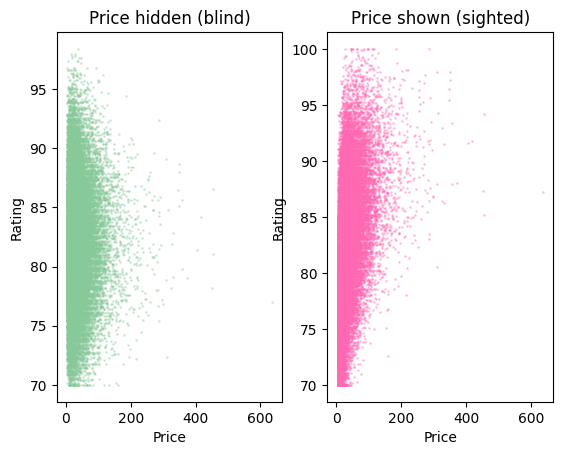

In [ ]:
# Blind Rating and Sighted Rating movement with price
def scatter_blind_sighted(df):
    plt.subplot(1, 2, 1)
    plt.scatter(df["price"], df["blind_rating"], s=1, alpha=0.3, color="#88c999")
    plt.title("Price hidden (blind)")
    plt.xlabel("Price")
    plt.ylabel("Rating")

    plt.subplot(1, 2, 2)
    plt.scatter(df["price"], df["sighted_rating"], s=1, alpha=0.3, color="hotpink")
    plt.title("Price shown (sighted)")
    plt.xlabel("Price")
    plt.ylabel("Rating")
    plt.show()

scatter_blind_sighted(df)

On the left (blind) the cloud is flat, so a higher price does not mean a higher rating. On the right (sighted) the cloud slopes upward meaning a pricier wine tends to have a higher rating.

## Average ratings per price group
We split the wines into 5 price groups and average each rating. `groupby` is not in the chapters, so we do it with a loop over the rows.

In [ ]:
def group_averages(df):  # Calculate average ratings for each price group
    # Initialize price groups and their rating totals
    labels = ["<10", "10-20", "20-40", "40-80", "80+"]
    count = [0, 0, 0, 0, 0]
    blind_total = [0, 0, 0, 0, 0]
    sighted_total = [0, 0, 0, 0, 0]

    # Classify wines by price and calculate rating totals
    for row in df.index:
        price = df.loc[row, "price"]
        if price < 10:
            group = 0
        elif price < 20:
            group = 1
        elif price < 40:
            group = 2
        elif price < 80:
            group = 3
        else:
            group = 4
        count[group] += 1
        blind_total[group] += df.loc[row, "blind_rating"]
        sighted_total[group] += df.loc[row, "sighted_rating"]

    # Calculate average ratings and their differences
    blind_avg = []
    sighted_avg = []
    difference = []
    for group in range(5):
        blind = blind_total[group] / count[group]
        sighted = sighted_total[group] / count[group]
        blind_avg.append(blind)
        sighted_avg.append(sighted)
        difference.append(sighted - blind)
        print(f"{labels[group]}: wines = {count[group]}, blind = {blind:.1f}, sighted = {sighted:.1f}, difference = {difference[group]:.1f}")

    return labels, blind_avg, sighted_avg, difference

# Run the function and retrieve the results
(labels, blind_avg, sighted_avg, difference) = group_averages(df)

<10: wines = 5685, blind = 81.5, sighted = 77.5, difference = -4.0
10-20: wines = 10313, blind = 81.9, sighted = 80.2, difference = -1.6
20-40: wines = 13064, blind = 82.2, sighted = 82.6, difference = 0.5
40-80: wines = 8157, blind = 82.2, sighted = 84.8, difference = 2.6
80+: wines = 2781, blind = 82.4, sighted = 87.2, difference = 4.9


**Difference** = sighted minus blind. Under 10 USD, people **lose 4 points** once they see the price. Over 80 USD, they **gain 4.9 points**. The blind averages stay almost constant (81.5 to 82.4).

## The charts

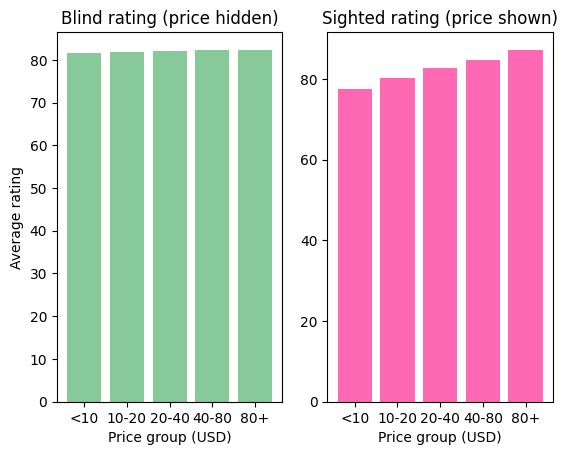

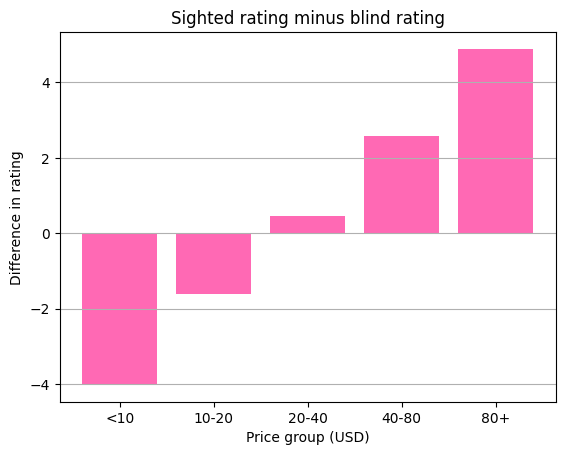

In [ ]:
def plot_groups(labels, blind_avg, sighted_avg):  # Compare blind and sighted ratings
    # Display the two average rating charts
    plt.subplot(1, 2, 1)
    plt.bar(labels, blind_avg, color="#88c999")
    plt.title("Blind rating (price hidden)")
    plt.xlabel("Price group (USD)")
    plt.ylabel("Average rating")

    plt.subplot(1, 2, 2)
    plt.bar(labels, sighted_avg, color="hotpink")
    plt.title("Sighted rating (price shown)")
    plt.xlabel("Price group (USD)")
    plt.show()

def plot_difference(labels, difference):  # Visualize the difference between ratings
    # Display the rating differences across price groups
    plt.bar(labels, difference, color="hotpink")
    plt.title("Sighted rating minus blind rating")
    plt.xlabel("Price group (USD)")
    plt.ylabel("Difference in rating")
    plt.grid(axis = "y")
    plt.show()

# Generate the charts
plot_groups(labels, blind_avg, sighted_avg)
plot_difference(labels, difference)

The green bars (blind) are the same height in every group. The pink bars (sighted) climb with the price. The second chart shows the effect directly: bars below 0 are wines people rate *lower* when they see a low price, bars above 0 are wines they rate *higher* when they see a high price.

##Blind vs Sighted Rating Conclusion

Price **strongly influences** how people rate wine, even when the taste is identical. That is why we study what determines price and try to estimate it.

# Price Factors

We test every candidate input one by one against price, then keep only those that are linked. Our candidates are the "production components" (winemaking_score, oak_months, residual_sugar, alcohol), the "climate" (vintage_quality), reputation (region_prestige), rarity (scarcity), the region's growing conditions (region_terroir).


In [ ]:
def price_drivers(df): # Get correlations between price and other factors
    columns = ["price", "winemaking_score", "oak_months", "residual_sugar", "alcohol", "region_prestige", "scarcity", "region_terroir", "vintage_quality"]
    table = df[columns].corr()
    print(table["price"])
price_drivers(df)

price               1.000000
winemaking_score    0.000957
oak_months          0.002024
residual_sugar      0.001001
alcohol             0.007099
region_prestige     0.442881
scarcity            0.418491
region_terroir      0.419255
vintage_quality     0.000707
Name: price, dtype: float64


Only three columns are linked to price: region_prestige (0.44), scarcity (0.42) and region_terroir (0.42). Everything else is about **0**: **vintage_quality, winemaking, oak, sugar, alcohol**, and also taste (**blind_rating**, 0.04).

**region_terroir** has the same value for every wine of a region, just like prestige, so it mostly repeats what prestige already tells us. We keep prestige and scarcity.

# How do the main factors compare?

Text(8, 0, '44.3%')

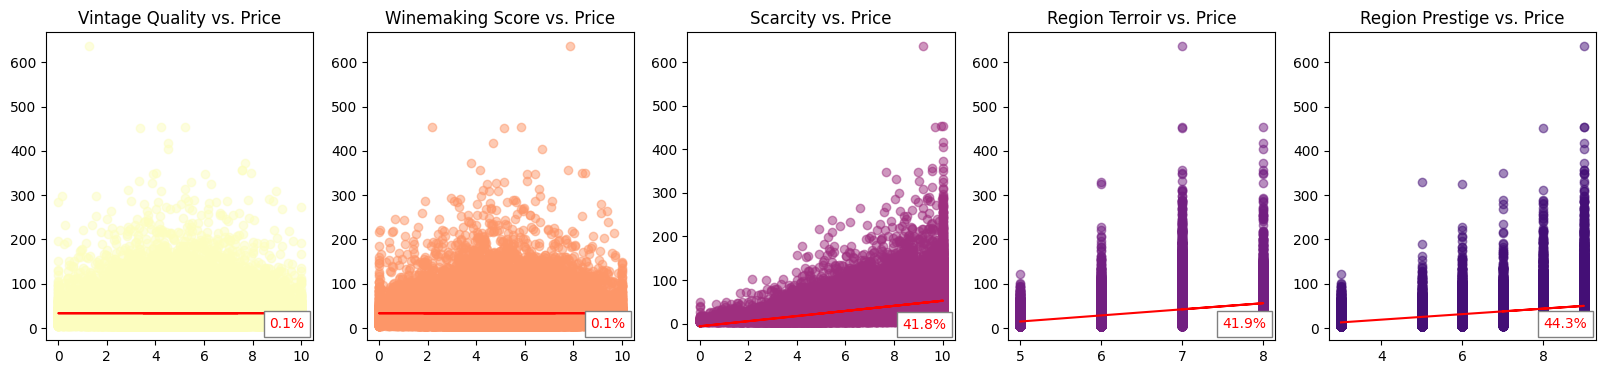

In [ ]:
# Create graphics to show the factors and their correlations
correlation = df[xVar].corrwith(df[yVar[0]])

# Found online how to set framework for subplots so all 5 fit together vs. using subplot()
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# Create regression function (can be as class i think)
def linearReg(x):
  return (slope * x) + intercept

# Formatting
colors = plt.cm.magma(np.linspace(0, 1, 10))

# Vintage Quality
x = np.array(df["vintage_quality"])
y = np.array(df["price"])

slope, intercept, r, p, std_err = stats.linregress(x, y)
mymodel = list(map(linearReg, x))

plt.subplot(1, 5, 1)
plt.scatter(x, y, color = colors[-1], alpha = 0.5)
plt.plot(x, mymodel, color = "red")
plt.title("Vintage Quality vs. Price")
plt.text( # show correlation with regression line
        x = 8.7,
        y = 0,
        s = (f"{correlation["vintage_quality"]:.1%}"),
        fontsize = 10,
        color= "red",
        bbox = dict(color = "white", ec = "grey")
        )

# Winemaking Score
x = np.array(df["winemaking_score"])
y = np.array(df["price"])

slope, intercept, r, p, std_err = stats.linregress(x, y)
mymodel = list(map(linearReg, x))

plt.subplot(1, 5, 2)
plt.scatter(x, y, color = colors[-3], alpha = 0.5)
plt.plot(x, mymodel, color = "red")
plt.title("Winemaking Score vs. Price")
plt.text( # show correlation with regression line
        x = 8.7,
        y = 0,
        s = (f"{correlation["winemaking_score"]:.1%}"),
        fontsize = 10,
        color= "red",
        bbox = dict(color = "white", ec = "grey")
        )
# Scarcity
x = np.array(df["scarcity"])
y = np.array(df["price"])

slope, intercept, r, p, std_err = stats.linregress(x, y)
mymodel = list(map(linearReg, x))

plt.subplot(1, 5, 3)
plt.scatter(x, y, color = colors[-6], alpha = 0.5)
plt.plot(x, mymodel, color = "red")
plt.title("Scarcity vs. Price")
plt.text( # show correlation with regression line
        x = 8.35,
        y = -12,
        s = (f"{correlation["scarcity"]:.1%}"),
        fontsize = 10,
        color = "red",
        bbox = dict(color = "white", ec = "grey")
        )

# Region Terroir
x = np.array(df["region_terroir"])
y = np.array(df["price"])

slope, intercept, r, p, std_err = stats.linregress(x, y)
mymodel = list(map(linearReg, x))

plt.subplot(1, 5, 4)
plt.scatter(x, y, color = colors[-7], alpha = 0.5)
plt.plot(x, mymodel, color = "red")
plt.title("Region Terroir vs. Price")
plt.text( # show correlation with regression line
        x = 7.5,
        y = 0,
        s = (f"{correlation["region_terroir"]:.1%}"),
        fontsize = 10,
        color= "red",
        bbox = dict(color = "white", ec = "grey")
        )

# Region Prestige
x = np.array(df["region_prestige"])
y = np.array(df["price"])

slope, intercept, r, p, std_err = stats.linregress(x, y)
mymodel = list(map(linearReg, x))

plt.subplot(1, 5, 5)
plt.scatter(x, y, color = colors[-8], alpha = 0.5)
b, a = np.polyfit(x, y, deg=1)
plt.plot(x, mymodel, color = "red")
plt.title("Region Prestige vs. Price")
plt.text( # show correlation with regression line
        x = 8,
        y = 0,
        s = (f"{correlation["region_prestige"]:.1%}"),
        fontsize = 10,
        color= "red",
        bbox = dict(color = "white", ec = "grey")
        )



# Now, follow the inputs below for your preferred bottle of wine

In [ ]:
# Pull the unique regions and cast as a list
region_unique = list(df["region"].unique())
region_unique.sort()

def userGenWine():

  # Print the regions available
  print(f"There are {len(region_unique)} regions in this study:\n")
  for i in region_unique:
    print(i)

  # Try/except statements to get correct user inputs for region and scarcity
  while True:
    try:
      user_region = str(input("\nSelect a region.\n"))

      if user_region in region_unique:
        print(f"You have selected the {user_region} region.\n")
        break # necessary to break loop and continue to the scarcity input
      else:
        print("This region does not exist!")

    except SyntaxError:
      print("Something is wrong with the variable name.")
    except NameError:
      print("Something is wrong with the variable name.")
    else:
      print("Nothing is wrong.")

  while True:
    try:
      user_scarcity = int(input("How important is scarcity to you from least to most important (0 - 10)?\n"))

      if 0 <= user_scarcity <= 10:
        print(f"You have selected a scarcity of {user_scarcity}.\n")
        return user_region, user_scarcity # return the variables for analysis
      else:
        print(f"You have entered an invalid input.\n")

    except SyntaxError:
      print("Something is wrong with the variable value.")
    except ValueError:
      print("Something is wrong with the variable value.")
    else:
      print("Nothing is wrong.")



# Call the function and assign the returned values to variables
user_region, user_scarcity = userGenWine()
print(f"\nYou would like to purchase a bottle of wine from the {user_region} region with a scarcity of {user_scarcity}.")

There are 8 regions in this study:

Barossa
Bordeaux
Burgundy
Generic New World
Mendoza
Napa
Rioja
Tuscany

Select a region.
Bordeaux
You have selected the Bordeaux region.

How important is scarcity to you from least to most important (0 - 10)?
10
You have selected a scarcity of 10.


You would like to purchase a bottle of wine from the Bordeaux region with a scarcity of 10.


In [ ]:
# Find all rows where user inputs match, using rounded integer scarcity
df_match = df.copy()
df_match['scarcity_binned'] = df_match['scarcity'].round().astype(int)

matching_user_inputs = df_match[
    (df_match['region'] == user_region) &
    (df_match['scarcity_binned'] == user_scarcity)
]

n_rows = len(matching_user_inputs)
print(f"Number of matching rows (rounded scarcity = {user_scarcity}): {n_rows}")

if n_rows > 0:
  mean_price = matching_user_inputs['price'].median()
  print(f"Median price: ${mean_price:.2f}\n")
else:
  print("No matching rows found.")

#matching_user_inputs['price'].max()

Number of matching rows (rounded scarcity = 10): 1191
Median price: $60.45



# Let's estimate the price you should pay for this bottle

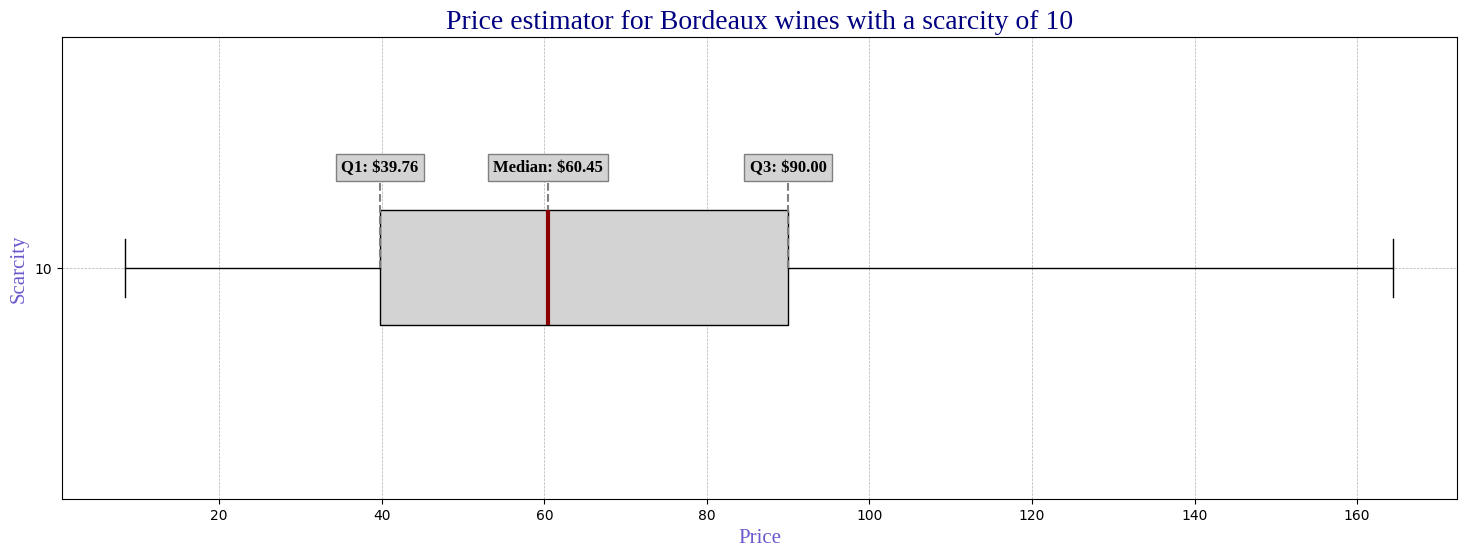

In [ ]:
# Font library
title_font = {'family':'Liberation Serif','color':'navy','size':20}
label_font = {'family':'Liberation Serif','color':'slateblue','size':15}
inner_label_font = {'family':'Liberation Serif','color':'black','size':12, 'weight':'bold'}

# Set figure size for the plot
plt.figure(figsize=(18, 6))

# Plot box and whisker plot and format so it is horizontal with a grey fill on interior patches
plt.boxplot(
    matching_user_inputs['price'],
    positions = [user_scarcity],
    widths = 0.25,
    vert = False,
    patch_artist = True,
    showfliers = False,

    # Formatting
    boxprops = dict(facecolor = "lightgrey"),
    medianprops=dict(color = "darkred", linewidth = 3),
    )

# Format the full box plot
plt.grid(linestyle = "--", linewidth = .5)
plt.title(f"Price estimator for {user_region} wines with a scarcity of {user_scarcity}", fontdict = title_font)
plt.xlabel("Price", fontdict = label_font)
plt.ylabel("Scarcity", fontdict = label_font)

# Stats for labels
q1 = np.percentile(matching_user_inputs['price'], 25)
median = np.median(matching_user_inputs['price'])
q3 = np.percentile(matching_user_inputs['price'], 75)
iqr = q3 - q1

# Stats to dictionary for label
stats_to_label = {
        f"Q1: ${q1:.2f}": q1,
        f"Median: ${median:.2f}": median,
        f"Q3: ${q3:.2f}": q3
    }

# Plot internal labels for interquartile range overtop of the existing box plot
for label, val in stats_to_label.items():
    plt.text(
        # Set placement values and string to input
        x = val,
        y = user_scarcity + .2,
        s = label,

        # Align and format internal labels
        ha = "center",
        va = "bottom",
        fontdict = inner_label_font,
        bbox = dict(color = "lightgrey", ec = "grey")
    )
    # Format boxes around internal labels
    plt.vlines(x = val, ymin = user_scarcity, ymax = user_scarcity + .2, colors = "grey", linestyles = "--")


In [ ]:
print(f"You may expect to pay within ${q1: .2f} to ${q3: .2f} for a wine from {user_region}, with a scarcity of {user_scarcity}, however the typical price for this bottle will cost around ${median: .2f} ")

You may expect to pay within $ 39.76 to $ 90.00 for a wine from Bordeaux, with a scarcity of 10, however the typical price for this bottle will cost around $ 60.45 


# Conclusion


We started with the full dataset: 40,000 wines from 8 regions, described by their price, their production characteristics and two ratings. The goal was to understand what the price of a wine really reflects.

##Step 1: Blind vs. sighted ratings
We first asked whether price and taste are linked, using the two ratings each wine has. When tasters could not see the price (blind rating), the correlation with price was almost zero (0.04). When they could see it (sighted rating), it rose to 0.43. Wines under 10 USD lost about 4 points once the price was visible, and wines over 80 USD gained about 5. So price strongly shapes how people rate a wine, but it does not follow taste.


##Step 2: The factors behind the price.
Since taste does not explain price, we tested the production and market factors one by one. Only region prestige (0.44), scarcity (0.42) and region terroir (0.42) are linked to price. Vintage quality, winemaking score, oak, sugar and alcohol are all about 0. Prestige and terroir are fixed for each region, so what matters comes down to two inputs: the region and how scarce the wine is.

##Step 3: Estimating a price from user input
We turned these two inputs into a tool. The user chooses a region and a scarcity level (0 to 10), and the program finds every wine with that region and scarcity and returns their average price giving the user a tool to facilitate pricing the wine.


## Limits:
Wines with the same region and scarcity still vary widely in price, so the result is a typical price and not an exact one.


## Overall, in this dataset the price of a wine reflects its reputation and its rarity, not how good it tastes.